# S13 · 排序分歧：换一套「热」的定义，高风险站点会变吗？

> **Day 13 / 14** ｜ 对应论文章节 **3.9 + 4.5（Definition sensitivity of risk ranking）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 理解为什么**风险排序**比风险水平更值得报告，也更可比
- 构造一个可加总的站点风险指标
- 定义 **RDI（Rank Disagreement Index）**，并且**先算清它的零分布**
- 用年重抽样 bootstrap 给出排序分歧的抽样不确定性
- 区分「定义真的改变了排序」和「指标本身不可跨定义比较」

---

## 1. 为什么讨论排序，而不是讨论水平

本研究用了三套「热」的定义：

| 定义 | 变量 | 物理含义 |
|---|---|---|
| `Tmax` | 日最高气温 | 白天干热 |
| `Tmin` | 日最低气温 | 夜间无法散热 |
| `Twmax` | 日最大湿球温度 | 湿热胁迫（人体真正感受到的） |

它们的**阈值各不相同**（每站每定义各自的日历日 90 百分位），
所以「Ipoh 的 Tmax 事件强度是 1.68 °C」和「Ipoh 的 Twmax 事件强度是 1.81 °C」
**不能直接比大小** —— 两个 °C 的含义都不一样。

但**排序**可以比：忽略了尺度，只问「谁比谁更糟」。

> 📌 论文里要写：「Because thresholds are station- and definition-specific, absolute
> exceedance magnitudes are not comparable across definitions. We therefore compare the
> **rankings** of stations, which are invariant to strictly increasing transformations of the
> risk metric (S08 §5).」

这也正是防灾决策实际需要的东西 —— 资源分配看的是「先管哪几个站」，不是「差 0.13 °C」。

---

## 2. 加载与聚合成站点级指标

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
ev <- load_catalogue()
d  <- load_clean_daily()
n_years <- length(unique(format(d$date, "%Y")))

agg <- do.call(rbind, lapply(split(ev, list(ev$station, ev$defn), drop = TRUE),
  function(g) data.frame(
    station    = g$station[1],
    defn       = g$defn[1],
    n_events   = nrow(g),
    rate       = nrow(g) / n_years,          # 事件 / 年
    mean_dur   = mean(g$duration),           # 天
    mean_int   = mean(g$intensity),          # °C
    sev_per_yr = sum(g$severity) / n_years   # °C·天 / 年
  )))

cat("站点数:", length(unique(agg$station)), " 定义数:", length(DEFS), "\n")
print(head(agg, 4), row.names = FALSE)

站点数: 10  定义数: 3 


           station defn n_events     rate mean_dur mean_int sev_per_yr
         Alor_Star Tmax       99 2.250000 4.393939 1.562458  10.135379
       Bayan_Lepas Tmax      112 2.545455 4.491071 1.679048  12.085682
 Cameron_Highlands Tmax      112 2.545455 4.223214 1.514970  10.675227
           Chuping Tmax       97 2.204545 4.577320 1.534502   9.624091


**为什么主指标选 `sev_per_yr`（年均累积超出量）？**

| 候选 | 问题 |
|---|---|
| 事件数 / 年 | 只看「发生几次」，不看每次多糟 |
| 平均时长 | 只看一个维度 |
| 平均强度 | 只看一个维度，且跨定义最不可比（见 §6） |
| **年均 severity** | `severity = Σ 超出量`，同时包含**频次 × 时长 × 强度**，且可加总到年 |

> 📌 `sev_per_yr` 的量纲是 °C·天/年，含义是「一年里累计有多少 °C·天处在阈值之上」。
> 它把「多少次」「多长」「多强」压缩成一个数，是风险排序最常用的综合量。

---

## 3. 排序

In [3]:
rank_matrix <- function(m) {
  w <- reshape(agg[, c("station", "defn", m)], idvar = "station",
               timevar = "defn", direction = "wide")
  M <- as.matrix(w[, paste0(m, ".", DEFS)])
  colnames(M) <- DEFS          # reshape 会给列加前缀（如 sev_per_yr.Tmax），这里去掉
  rownames(M) <- w$station
  apply(M, 2, function(v) rank(-v, ties.method = "average"))   # 越大 → 排名越靠前(1)
}

R_sev <- rank_matrix("sev_per_yr")
print(R_sev)

                  Tmax Tmin Twmax
Alor_Star            7    8     6
Bayan_Lepas          2    1     2
Cameron_Highlands    6    4     7
Chuping              8    9     8
Ipoh                 1    2     1
Kluang               4    7     5
Kota_Bharu           9    6     9
Kuala_Krai           5    3     4
Kuantan             10   10    10
Langkawi             3    5     3


> 🔍 先肉眼扫一遍：`Kuantan` 三列都是 10，`Ipoh` 是 1/2/1。
> 而 `Cameron_Highlands` 是 6/4/7 —— 它看起来「一般」，但如果只看 Tmin，
> 它会排到第 4。**高原站是最容易出现定义分歧的地方**（夜间降温快，但湿球温度也低）。

---

## 4. 图：排序连线（bump chart）

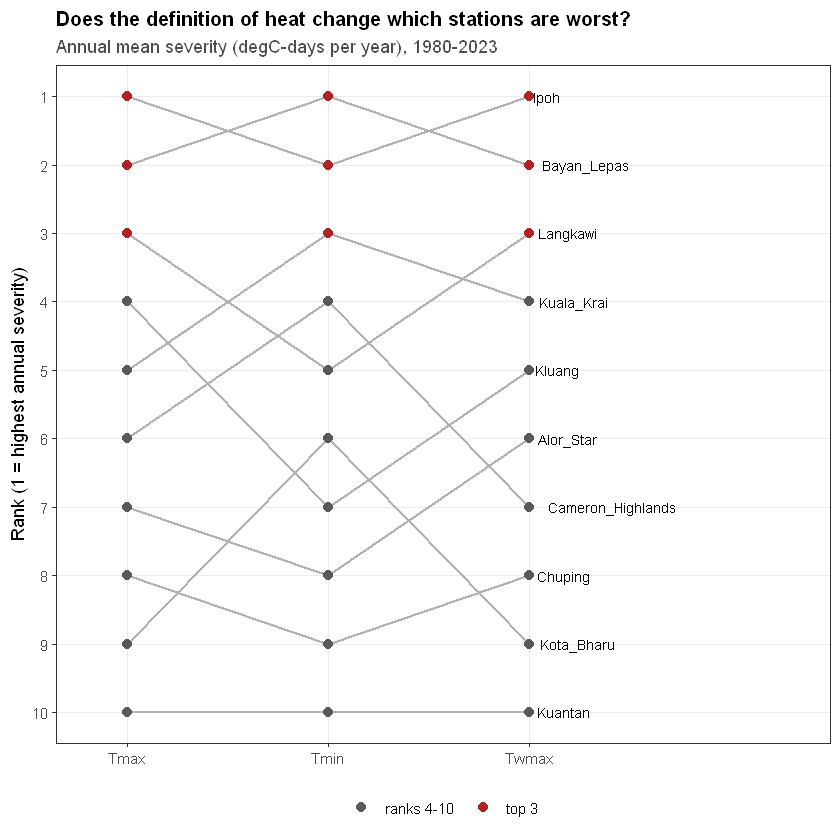

In [4]:
rank_long <- data.frame(
  station = rep(rownames(R_sev), times = ncol(R_sev)),
  defn    = rep(colnames(R_sev), each = nrow(R_sev)),
  rank    = as.vector(R_sev)
)
rank_long$defn <- factor(rank_long$defn, levels = DEFS)

p_bump <- ggplot(rank_long, aes(defn, rank, group = station)) +
  geom_line(colour = "grey70", linewidth = 0.6) +
  geom_point(aes(colour = rank <= 3), size = 2.4) +
  geom_text(data = subset(rank_long, defn == DEFS[length(DEFS)]),
            aes(label = station), hjust = -0.15, size = 3) +
  scale_y_reverse(breaks = 1:10) +
  scale_x_discrete(expand = expansion(add = c(0.35, 1.5))) +
  scale_colour_manual(values = c(`TRUE` = "firebrick", `FALSE` = "grey35"),
                      labels = c(`TRUE` = "top 3", `FALSE` = "ranks 4-10"),
                      name = NULL) +
  labs(x = NULL, y = "Rank (1 = highest annual severity)",
       title = "Does the definition of heat change which stations are worst?",
       subtitle = sprintf("Annual mean severity (degC-days per year), %s-%s",
                          min(format(d$date, "%Y")), max(format(d$date, "%Y")))) +
  theme_paper()

save_fig(p_bump, "S13_rank_bump", 7, 5)
p_bump

> 🔍 **读法**：线越平，说明这个站在不同定义下的地位越稳定。
> 交叉最多的线段就是**定义敏感**的站点 —— 这恰恰是论文里最该点名的。
>
> ⚠️ 肉眼只能看出「大致像」，看不出「像到什么程度才算真的像」。
> 这正是下一节要解决的问题。

---

## 5. RDI 与它必须先算清的零分布

**RDI（Rank Disagreement Index）**：

$$\mathrm{RDI}(A,B) = \frac{\sum_{i=1}^{n} |r^A_i - r^B_i|}{n^2/2}$$

- 完全相同 → 0
- 完全反转 → 1
- **n = 10 时，「完全无关」→ 不是 0，而是 0.66**

In [5]:
set.seed(CFG$seed)
n_st <- nrow(R_sev)

# 零分布：两套排序相互独立时，RDI 会是多少？
rdi_null <- replicate(20000, rdi(sample(n_st), sample(n_st)))

cat("n =", n_st, "时，独立排序下的 RDI ：\n")
cat(sprintf("  均值 %.3f，标准差 %.3f\n", mean(rdi_null), sd(rdi_null)))
cat(sprintf("  5%% - 95%% 区间：%.3f - %.3f\n",
            quantile(rdi_null, 0.05), quantile(rdi_null, 0.95)))

n = 10 时，独立排序下的 RDI ：


  均值 0.661，标准差 0.143


  5% - 95% 区间：0.400 - 0.880


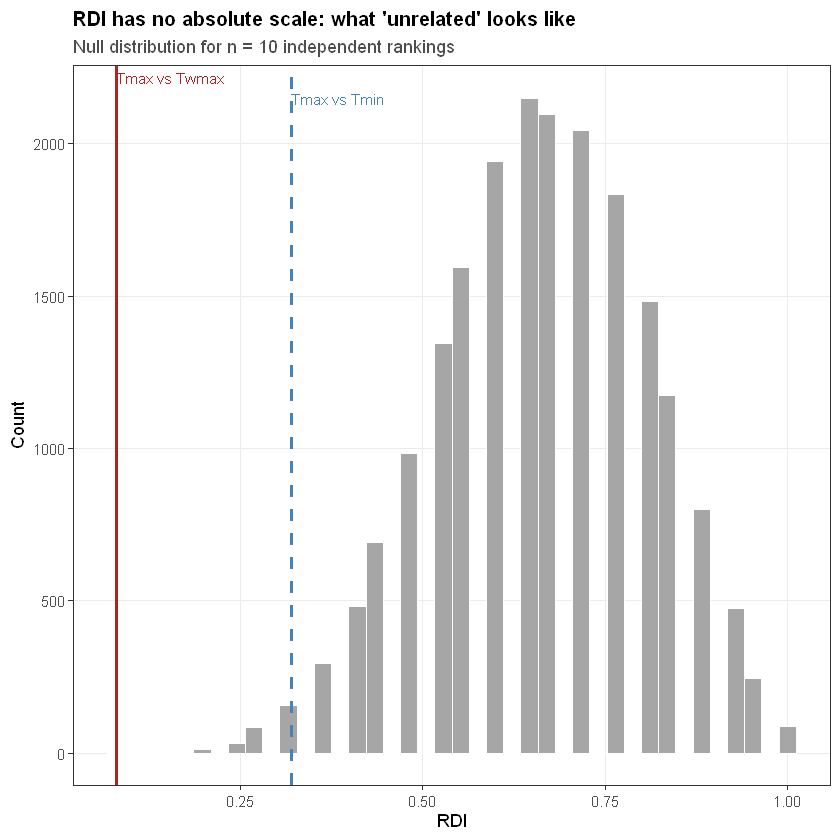

In [6]:
p_null <- ggplot(data.frame(x = rdi_null), aes(x)) +
  geom_histogram(bins = 40, fill = "grey65", colour = "white") +
  geom_vline(xintercept = rdi(R_sev[, "Tmax"], R_sev[, "Twmax"]),
             colour = "firebrick", linewidth = 1) +
  geom_vline(xintercept = rdi(R_sev[, "Tmax"], R_sev[, "Tmin"]),
             colour = "steelblue", linewidth = 1, linetype = "dashed") +
  annotate("text", x = 0.08, y = Inf, label = "Tmax vs Twmax",
           colour = "firebrick", vjust = 1.5, hjust = 0, size = 3.2) +
  annotate("text", x = 0.32, y = Inf, label = "Tmax vs Tmin",
           colour = "steelblue", vjust = 3.2, hjust = 0, size = 3.2) +
  labs(x = "RDI", y = "Count",
       title = "RDI has no absolute scale: what 'unrelated' looks like",
       subtitle = sprintf("Null distribution for n = %d independent rankings", n_st)) +
  theme_paper()

save_fig(p_null, "S13_rdi_null", 6.5, 4)
p_null

> 🚨 **这是整节最重要的一张图。**
>
> 如果只看「RDI = 0.32，离 0 还有距离」就下结论「排序不一致」，
> 那是错的 —— 因为**独立随机排序的平均 RDI 就是 0.66**。
> 真正的参照系是这条灰色分布，**不是 0**。
>
> 只有把观测值放到这条分布上，才能说「比随机更一致」还是「和随机没区别」。
> 这是所有「一致性指数」类指标（包括 Jaccard、ARI）的共同陷阱。

---

## 6. 指标不同，结论完全不同

In [7]:
metrics <- c(sev_per_yr = "Annual severity",
             rate       = "Event rate",
             mean_int   = "Mean intensity",
             mean_dur   = "Mean duration")

rdi_tab <- do.call(rbind, lapply(names(metrics), function(m) {
  R <- rank_matrix(m)
  do.call(rbind, lapply(list(c(1, 2), c(1, 3), c(2, 3)), function(pp) {
    data.frame(metric    = m,
               pair      = paste(DEFS[pp[1]], "vs", DEFS[pp[2]]),
               RDI       = round(rdi(R[, pp[1]], R[, pp[2]]), 3),
               spearman  = round(cor(R[, pp[1]], R[, pp[2]], method = "spearman"), 2),
               kendall   = round(cor(R[, pp[1]], R[, pp[2]], method = "kendall"), 2))
  }))
}))

# 按指标分组打印，方便对照
for (m in names(metrics)) {
  cat("\n---", metrics[m], "---\n", sep = "")
  print(rdi_tab[rdi_tab$metric == m, c("pair", "RDI", "spearman", "kendall")],
        row.names = FALSE)
}


---Annual severity---
          pair  RDI spearman kendall
  Tmax vs Tmin 0.32     0.79    0.64
 Tmax vs Twmax 0.08     0.98    0.91
 Tmin vs Twmax 0.32     0.79    0.64

---Event rate---
          pair  RDI spearman kendall
  Tmax vs Tmin 0.20     0.92    0.81
 Tmax vs Twmax 0.28     0.83    0.69
 Tmin vs Twmax 0.40     0.70    0.51

---Mean intensity---
          pair  RDI spearman kendall
  Tmax vs Tmin 0.76    -0.12   -0.07
 Tmax vs Twmax 0.72     0.09    0.11
 Tmin vs Twmax 0.64     0.02    0.02

---Mean duration---
          pair  RDI spearman kendall
  Tmax vs Tmin 0.56     0.37    0.29
 Tmax vs Twmax 0.64     0.15    0.11
 Tmin vs Twmax 0.48     0.39    0.38


> 🔍 **三种完全不同的图案，每一种都有话说：**
>
> | 指标 | RDI 范围 | ρ | 解释 |
> |---|---|---|---|
> | **年均 severity** | 0.08 – 0.32 | 0.79 – 0.98 | 三套定义高度一致，排序**稳健** |
> | **事件率** | 0.20 – 0.40 | 0.70 – 0.92 | 一致，但比 severity 弱 |
> | **平均强度** | 0.64 – 0.76 | −0.12 – 0.09 | **和随机排序没区别** |
> | **平均时长** | 0.48 – 0.64 | 0.15 – 0.39 | 弱一致，接近随机 |
>
> **为什么 severity 一致而 intensity 不一致？**
> 因为 severity 主要由「事件率 × 典型规模」决定，而事件率在百分位阈值下**天然被拉平**；
> 平均强度则取决于每个变量上尾的形状 —— Tmax 上尾长、Twmax 上尾短且接近物理上限。
> **两个不可比的尺子排出来的序，本来就该无关。**
>
> 📌 这反过来给了一个重要判断：**如果论文的结论建立在「平均强度排序」上，那它不稳。**
> 建立在「年均 severity 排序」上则稳得多。

---

## 7. 抽样不确定性：年重抽样 bootstrap

上面的 RDI 是**点估计**，只用了这一批 44 年。换个 44 年样本，排序会怎么变？

In [8]:
st <- rownames(R_sev)
yrs <- sort(unique(format(d$date, "%Y")))
ev$yr <- format(ev$start_date, "%Y")

# 每站每定义的「年 severity 矩阵」：行=站，列=年
annual <- lapply(DEFS, function(dn) {
  g <- ev[ev$defn == dn, ]
  M <- tapply(g$severity, list(factor(g$station, levels = st), g$yr), sum)
  M[is.na(M)] <- 0
  M[, yrs, drop = FALSE]
})
names(annual) <- DEFS

set.seed(CFG$seed)
B <- 2000
boot_rdi <- replicate(B, {
  idx <- sample.int(length(yrs), length(yrs), replace = TRUE)   # 重抽年份
  r <- sapply(DEFS, function(dn) rank(-rowMeans(annual[[dn]][, idx, drop = FALSE])))
  c(rdi(r[, 1], r[, 2]), rdi(r[, 1], r[, 3]), rdi(r[, 2], r[, 3]))
})

boot_sum <- data.frame(
  pair   = c(paste(DEFS[1], "vs", DEFS[2]),
             paste(DEFS[1], "vs", DEFS[3]),
             paste(DEFS[2], "vs", DEFS[3])),
  point  = c(rdi(R_sev[, 1], R_sev[, 2]),
             rdi(R_sev[, 1], R_sev[, 3]),
             rdi(R_sev[, 2], R_sev[, 3])),
  median = apply(boot_rdi, 1, median),
  lo     = apply(boot_rdi, 1, quantile, 0.025),
  hi     = apply(boot_rdi, 1, quantile, 0.975)
)
boot_sum[, 2:5] <- round(boot_sum[, 2:5], 3)
print(boot_sum, row.names = FALSE)

          pair point median    lo   hi
  Tmax vs Tmin  0.32   0.32 0.120 0.56
 Tmax vs Twmax  0.08   0.20 0.079 0.44
 Tmin vs Twmax  0.32   0.36 0.120 0.64


> 🚨 **注意 `point` 和 `median` 不一样，这不是 bug。**
>
> `rdi` 有下界 0，而且当两套排序几乎完全一致时，点估计**正好贴着下界**。
> 重抽年份会让排序抖动，抖动只会把 RDI **往大推**（不可能更小）。
> 于是 bootstrap 分布是右偏的，中位数高于点估计。
>
> 正确的解读是：
> - 点估计 0.08 = 「在这 44 年里，两套排序（几乎）相同」
> - 区间 [0.08, 0.44] = 「换一个 44 年样本，分歧可能大到什么程度」
> - **两者回答的是不同问题**，都要报，不要只挑一个
>
> 📌 论文写法：「The observed severity rankings for Tmax and Twmax disagree minimally
> (RDI = 0.08, Spearman ρ = 0.98). A year-block bootstrap, which resamples the 44 hydrological
> years with replacement, yields a 95% interval of [0.08, 0.44], indicating that the close
> agreement is real in this record but not tight enough to claim definition-invariance of the
> ranking at the 10-station scale.」

---

## 8. 政策相关的两个量：前三名与排名跨度

In [9]:
top3 <- sapply(DEFS, function(dn) {
  s <- agg[agg$defn == dn, ]
  head(s$station[order(-s$sev_per_yr)], 3)
})
print(top3)

common <- Reduce(intersect, as.list(as.data.frame(top3)))
cat("\n三套定义共同的前三名:", paste(common, collapse = ", "), "\n")
cat("共同前三名的个数:", length(common), "/ 3\n")

spread <- apply(R_sev, 1, function(x) max(x) - min(x))
cat("\n排名跨度（跨三套定义）:\n")
print(sort(spread, decreasing = TRUE))

     Tmax          Tmin          Twmax        
[1,] "Ipoh"        "Bayan_Lepas" "Ipoh"       
[2,] "Bayan_Lepas" "Ipoh"        "Bayan_Lepas"
[3,] "Langkawi"    "Kuala_Krai"  "Langkawi"   



三套定义共同的前三名: Ipoh, Bayan_Lepas 


共同前三名的个数: 2 / 3



排名跨度（跨三套定义）:


Cameron_Highlands            Kluang        Kota_Bharu         Alor_Star 
                3                 3                 3                 2 
       Kuala_Krai          Langkawi       Bayan_Lepas           Chuping 
                2                 2                 1                 1 
             Ipoh           Kuantan 
                1                 0 


> 📌 **`common` 这个量比 RDI 更直观，也更容易写进摘要。**
> 「无论采用 Tmax、Tmin 还是 Twmax，Ipoh 与 Bayan Lepas 始终位列前三」——
> 这句话政策部门看得懂，RDI = 0.08 他们看不懂。
>
> **两个都报**：RDI 给方法学的严谨性，前三名交集给决策者的可操作性。

---

## 9. 保存

In [10]:
rank_out <- data.frame(station = rownames(R_sev),
                       Tmax = R_sev[, "Tmax"],
                       Tmin = R_sev[, "Tmin"],
                       Twmax = R_sev[, "Twmax"],
                       spread_across_defns = spread)

write.csv(rank_out, file.path(PATHS$mres, "table6_definition_ranks.csv"), row.names = FALSE)
write.csv(rdi_tab,  file.path(PATHS$mres, "table6b_rdi.csv"), row.names = FALSE)
write.csv(boot_sum, file.path(PATHS$mres, "table6c_rdi_bootstrap.csv"), row.names = FALSE)
cat("已保存 table6_definition_ranks.csv / table6b_rdi.csv / table6c_rdi_bootstrap.csv\n")

已保存 table6_definition_ranks.csv / table6b_rdi.csv / table6c_rdi_bootstrap.csv


---

## 10. 常见错误

| 错误 | 后果 |
|---|---|
| 用 RDI 的绝对值下结论（「0.3 不小」） | 忽略零分布：n=10 时随机就有 0.66 |
| 把「平均强度」的排序当风险排序 | 该指标跨定义不可比，结论不稳 |
| 只报点估计不报 bootstrap | 44 年样本的排序抖动被隐藏 |
| 把 bootstrap 中位数当点估计 | 有界统计量的 bootstrap 分布是右偏的 |
| 用不同定义的绝对强度互相比较 | °C 的含义不同，比较无意义 |
| 排名出现平局却不处理 | `rank()` 默认 average，需在方法里说明 |
| 只报 RDI 不报前三名交集 | 决策者看不懂，也无法落地 |

---

## 11. 自检问题

<details>
<summary>Q1：为什么 n = 10 时「完全无关」的 RDI 是 0.66 而不是 0？</summary>

因为 RDI 衡量的是两套排序之间的**平均绝对秩差**。即使两套排序完全独立随机，10 个站点里也必然有一些站点的名次相差很大（第一名和第十名的期望差是 3.3）。把这些差加起来除以 `n²/2 = 50`，得到 0.66。所以 RDI 的正确用法是**和零分布比**，不是和 0 比。

</details>

<details>
<summary>Q2：既然 severity 排序很稳，为什么平均强度排序完全无关？</summary>

因为「强度」在三套定义里量的是**不同的物理量**：Tmax 的超出量以空气温度的 °C 计，Twmax 的超出量以湿球温度的 °C 计，而后者的分布被物理上限压得更紧。排序是在**各自尺度内**做的，但各自尺度的**形状**不同，所以排出来的序不会有共同结构。severity 之所以稳，是因为它被事件率主导，而事件率在百分位阈值下按构造被拉平。

**这条结论本身很有价值**：它说明「同一个站更热」这件事，在不同定义下并不同构。

</details>

<details>
<summary>Q3：bootstrap 的中位数（0.20）比点估计（0.08）高，是不是算错了？</summary>

不是。RDI 有下界 0，点估计贴着下界。重抽样只会让排序抖动、RDI 单向变大，分布右偏，中位数自然高于点估计。这恰恰说明**点估计本身就是「最一致」的那个极端情况**。

</details>

<details>
<summary>Q4：能不能直接说「本研究的风险排序对定义不敏感」？</summary>

只有在同时满足两条时才能说：(1) RDI 显著低于零分布；(2) bootstrap 上界仍然不大。本例 Tmax vs Twmax 的 RDI = 0.08（远低于 0.66），但 bootstrap 上界到 0.44 —— 所以稳妥的说法是「在现有记录中高度一致，但在 10 站规模下不足以声称定义无关」，并用前三名交集做补充证据。

</details>

<details>
<summary>Q5：为什么 bootstrap 要按「年」重抽，而不是按「事件」重抽？</summary>

因为同一年内的事件高度相关（同一个季风季、同一次 ENSO 事件）。按事件重抽会破坏这种相关，低估不确定性。按年整块重抽保留了年内相关，是气候序列的标准做法（block bootstrap 的最简形式）。

</details>

---

## 下一步

**S14 · 稳健性、时变阈值与写作**：把前面 13 天的所有「如果换一种做法会怎样」集中回答一遍，
并给出论文 Results / Discussion 的段落模板。